In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import RobustScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import accuracy_score
import time
from sklearn.metrics import accuracy_score, roc_auc_score

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, f1_score
from sklearn.metrics import
from sklearn.metrics import
from sklearn.metrics import precision_score
from sklearn.metrics import roc_curve, auc
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import export_graphviz
import graphviz
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import OneHotEncoder
from imblearn.over_sampling import SMOTE


In [ ]:
SEED=2
np.random.seed(SEED)
df = pd.read_csv(r"/content/bank_data.csv", sep=';', quotechar='"')
display(df)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [ ]:
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [ ]:
df.isnull().sum()

,0
age,0
job,0
marital,0
education,0
default,0
housing,0
loan,0
contact,0
month,0
day_of_week,0


In [ ]:
df.nunique()

,0
age,78
job,12
marital,4
education,8
default,3
housing,3
loan,3
contact,2
month,10
day_of_week,5


In [ ]:
df.corr(numeric_only=True)

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
age,1.000000,-0.000866,0.004594,-0.034369,0.024365,-0.000371,0.000857,0.129372,0.010767,-0.017725
duration,-0.000866,1.000000,-0.071699,-0.047577,0.020640,-0.027968,0.005312,-0.008173,-0.032897,-0.044703
campaign,0.004594,-0.071699,1.000000,0.052584,-0.079141,0.150754,0.127836,-0.013733,0.135133,0.144095
pdays,-0.034369,-0.047577,0.052584,1.000000,-0.587514,0.271004,0.078889,-0.091342,0.296899,0.372605
previous,0.024365,0.020640,-0.079141,-0.587514,1.000000,-0.420489,-0.203130,-0.050936,-0.454494,-0.501333
emp.var.rate,-0.000371,-0.027968,0.150754,0.271004,-0.420489,1.000000,0.775334,0.196041,0.972245,0.906970
cons.price.idx,0.000857,0.005312,0.127836,0.078889,-0.203130,0.775334,1.000000,0.058986,0.688230,0.522034
cons.conf.idx,0.129372,-0.008173,-0.013733,-0.091342,-0.050936,0.196041,0.058986,1.000000,0.277686,0.100513
euribor3m,0.010767,-0.032897,0.135133,0.296899,-0.454494,0.972245,0.688230,0.277686,1.000000,0.945154
nr.employed,-0.017725,-0.044703,0.144095,0.372605,-0.501333,0.906970,0.522034,0.100513,0.945154,1.000000


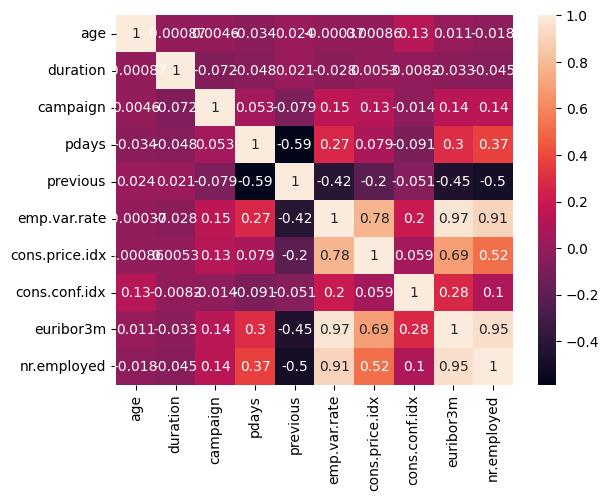

In [ ]:
sns.heatmap(df.corr(numeric_only=True), annot = True)
plt.rcParams['figure.figsize'] = (40,10)
plt.show()

<Axes: >

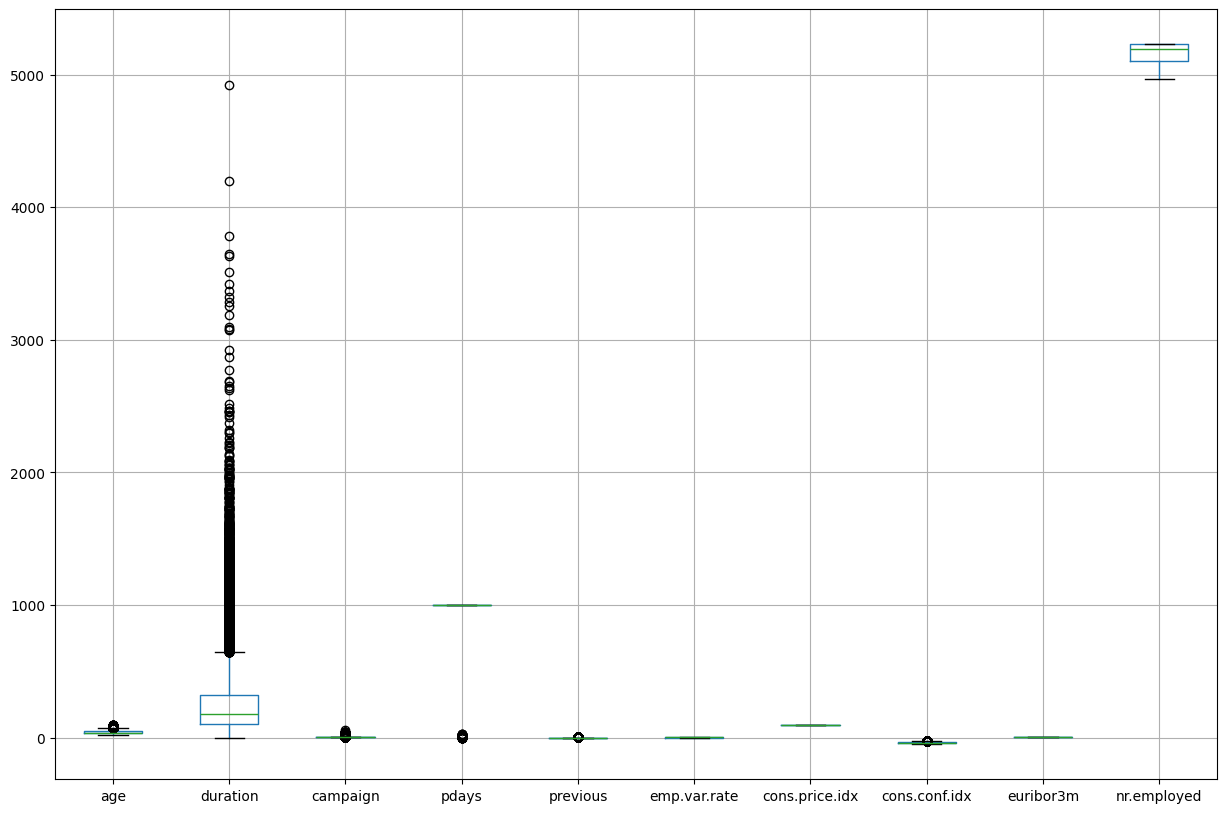

In [ ]:
df.boxplot(figsize=(15,10))

In [ ]:
df[df['duration']>4000]

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
22192,52,blue-collar,married,basic.4y,no,no,no,telephone,aug,thu,...,3,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,yes
24091,33,technician,single,professional.course,no,yes,no,telephone,nov,mon,...,1,999,0,nonexistent,-0.1,93.200,-42.0,4.406,5195.8,no


In [ ]:
print('job:',df['job'].unique())
print('marital:',df['marital'].unique())
print('education:',df['education'].unique())
print('default:',df['default'].unique())
print('housing:',df['housing'].unique())
print('loan:',df['loan'].unique())
print('contact:',df['contact'].unique())
print('month:',df['month'].unique())
print('day_of_week:',df['day_of_week'].unique())
print('poutcome:',df['poutcome'].unique())
print('y:',df['y'].unique())

job: ['housemaid' 'services' 'admin.' 'blue-collar' 'technician' 'retired'
 'management' 'unemployed' 'self-employed' 'unknown' 'entrepreneur'
 'student']
marital: ['married' 'single' 'divorced' 'unknown']
education: ['basic.4y' 'high.school' 'basic.6y' 'basic.9y' 'professional.course'
 'unknown' 'university.degree' 'illiterate']
default: ['no' 'unknown' 'yes']
housing: ['no' 'yes' 'unknown']
loan: ['no' 'yes' 'unknown']
contact: ['telephone' 'cellular']
month: ['may' 'jun' 'jul' 'aug' 'oct' 'nov' 'dec' 'mar' 'apr' 'sep']
day_of_week: ['mon' 'tue' 'wed' 'thu' 'fri']
poutcome: ['nonexistent' 'failure' 'success']
y: ['no' 'yes']


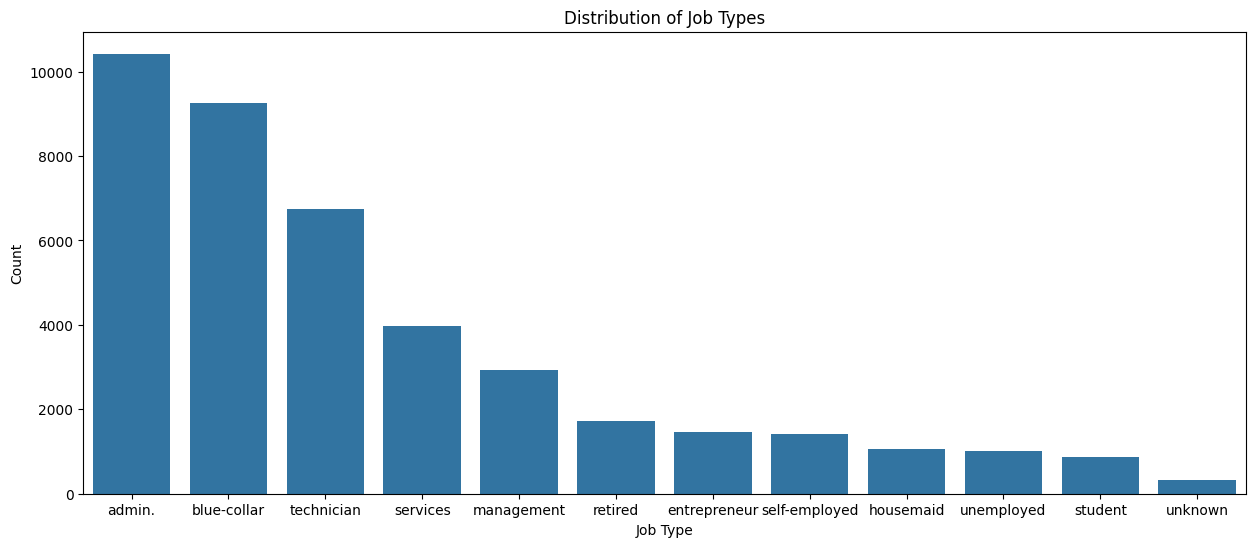

mean is:  3432.3333333333335
Management


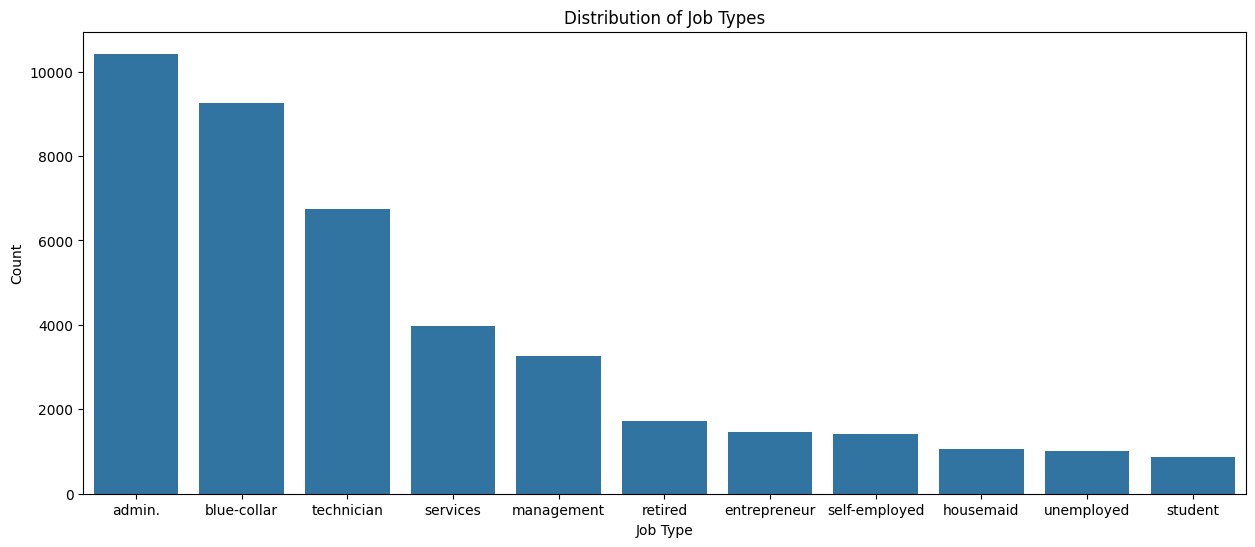

In [ ]:
df[df['job'].str.contains('unknown')]
df[df['job'].str.contains('unknown')].count() # 330 unknown value

plt.figure(figsize=(15, 6))
sns.countplot(x='job', data=df, order = df['job'].value_counts().index)
plt.title('Distribution of Job Types')
plt.ylabel('Count')
plt.xlabel('Job Type')
plt.show()

job_counts = df['job'].value_counts()
mean_job_count = job_counts.mean()
print("mean is: ",mean_job_count)

difference=[]
for i in range (len(df['job'].unique())):
  difference.append(abs(job_counts.iloc[i] - mean_job_count))

min_diff=np.min(difference)
replace_job_title=''
for j in range(len(difference)):
  if difference[j]==min_diff:
    replace_job_title=job_counts.index[j].title()
    print(replace_job_title)

#replacing unknown values with management
df['job'] = df['job'].replace('unknown',replace_job_title.lower())

plt.figure(figsize=(15, 6))
sns.countplot(x='job', data=df, order = df['job'].value_counts().index)
plt.title('Distribution of Job Types')
plt.ylabel('Count')
plt.xlabel('Job Type')
plt.show()




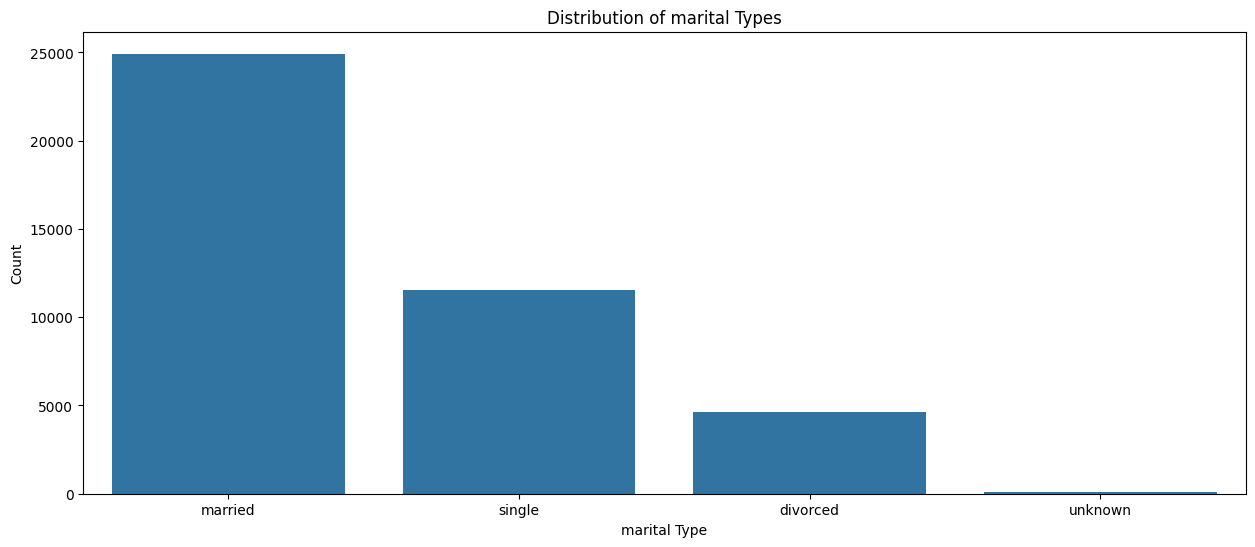

mean is:  10297.0
Single


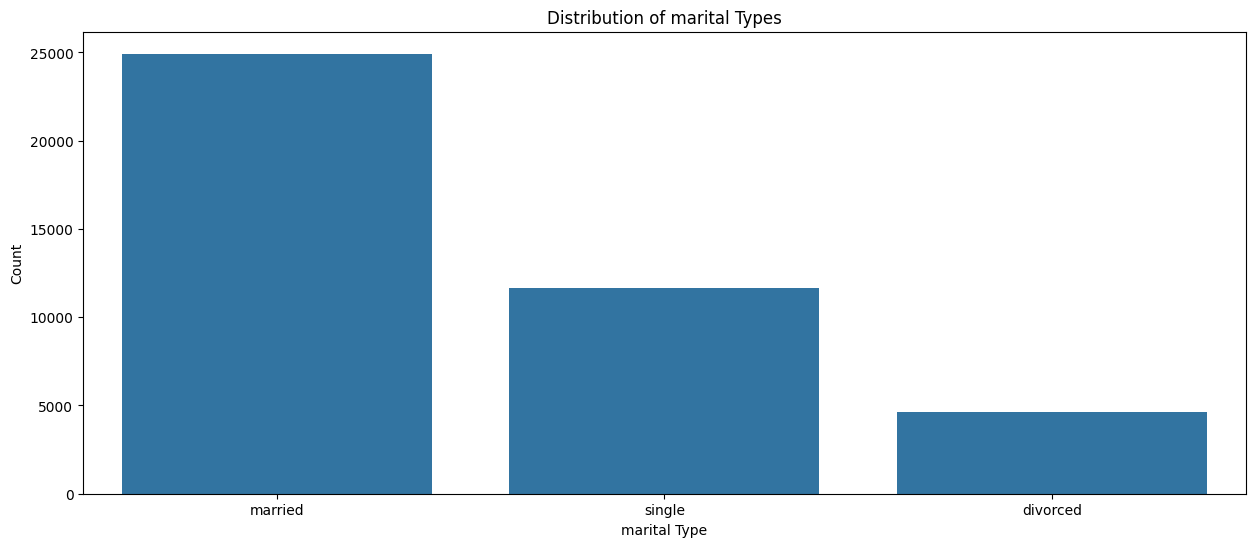

In [ ]:
df[df['marital'].str.contains('unknown')].count()
df[df['marital'].str.contains('unknown')]

plt.figure(figsize=(15, 6))
sns.countplot(x='marital', data=df, order = df['marital'].value_counts().index)
plt.title('Distribution of marital Types')
plt.ylabel('Count')
plt.xlabel('marital Type')
plt.show()

marital_counts = df['marital'].value_counts()
mean_marital_count = marital_counts.mean()
print("mean is: ",mean_marital_count)

difference=[]
for i in range (len(df['marital'].unique())):
  difference.append(abs(marital_counts.iloc[i] - mean_marital_count))

min_diff=np.min(difference)
replace_marital_title=''
for j in range(len(difference)):
  if difference[j]==min_diff:
    replace_marital_title=marital_counts.index[j].title()
    print(replace_marital_title)

#replacing unknown values with single
df['marital'] = df['marital'].replace('unknown',replace_marital_title.lower())

plt.figure(figsize=(15, 6))
sns.countplot(x='marital', data=df, order = df['marital'].value_counts().index)
plt.title('Distribution of marital Types')
plt.ylabel('Count')
plt.xlabel('marital Type')
plt.show()

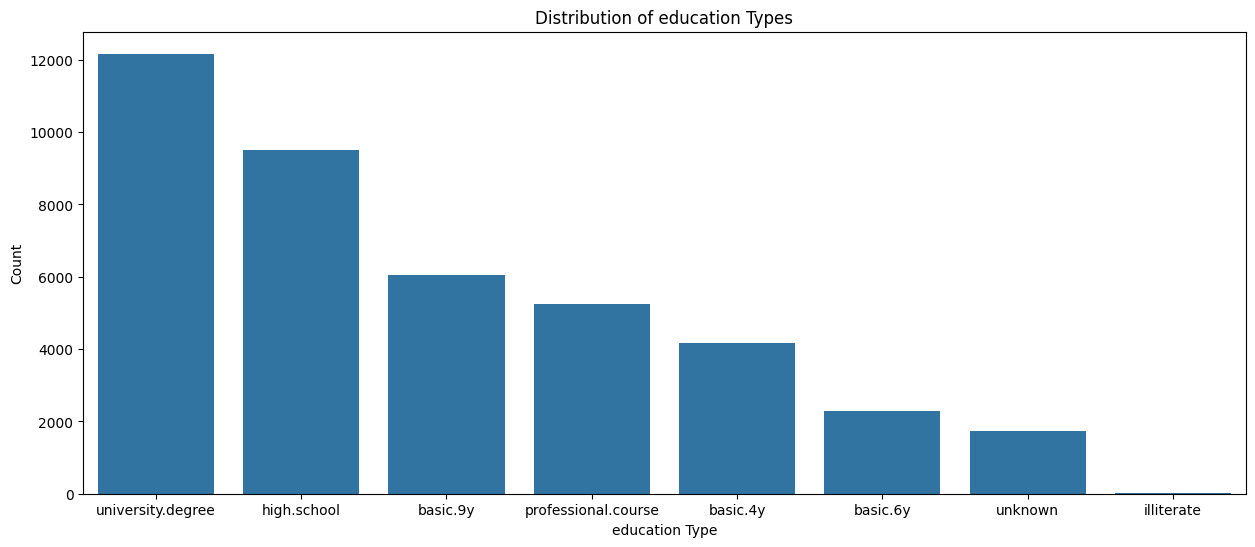

mean is:  5148.5
Professional.Course


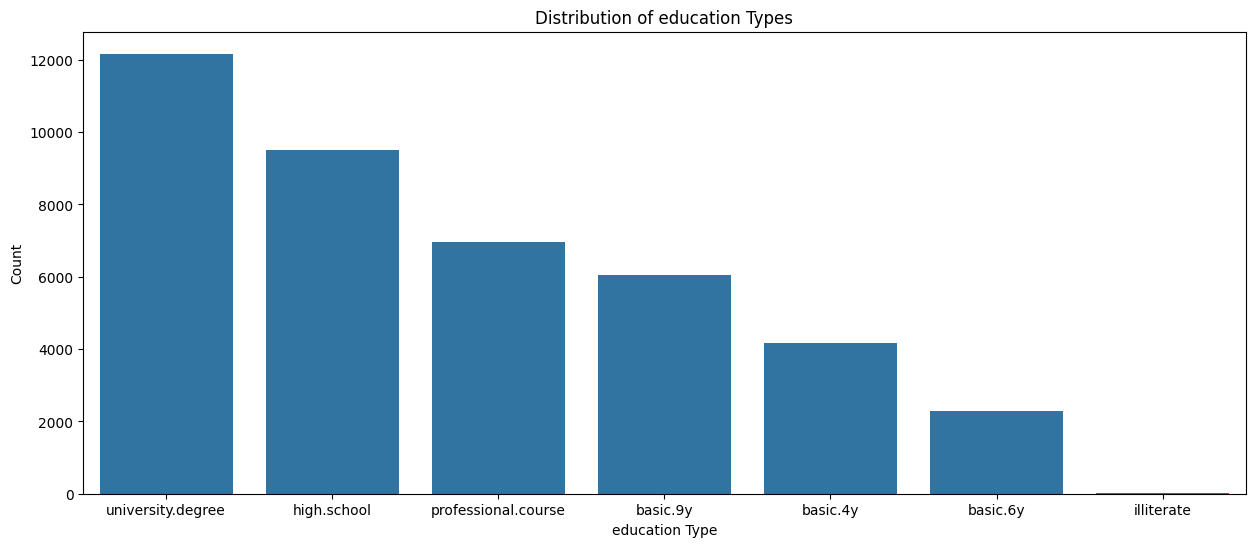

In [ ]:
df[df['education'].str.contains('unknown')].count()
df[df['education'].str.contains('unknown')]

plt.figure(figsize=(15, 6))
sns.countplot(x='education', data=df, order = df['education'].value_counts().index)
plt.title('Distribution of education Types')
plt.ylabel('Count')
plt.xlabel('education Type')
plt.show()

education_counts = df['education'].value_counts()
mean_education_count = education_counts.mean()
print("mean is: ",mean_education_count)

difference=[]
for i in range (len(df['education'].unique())):
  difference.append(abs(education_counts.iloc[i] - mean_education_count))

min_diff=np.min(difference)
replace_education_title=''
for j in range(len(difference)):
  if difference[j]==min_diff:
    replace_education_title=education_counts.index[j].title()
    print(replace_education_title)

#replacing unknown values with Professional.Course
df['education'] = df['education'].replace('unknown',replace_education_title.lower())

plt.figure(figsize=(15, 6))
sns.countplot(x='education', data=df, order = df['education'].value_counts().index)
plt.title('Distribution of education Types')
plt.ylabel('Count')
plt.xlabel('education Type')
plt.show()


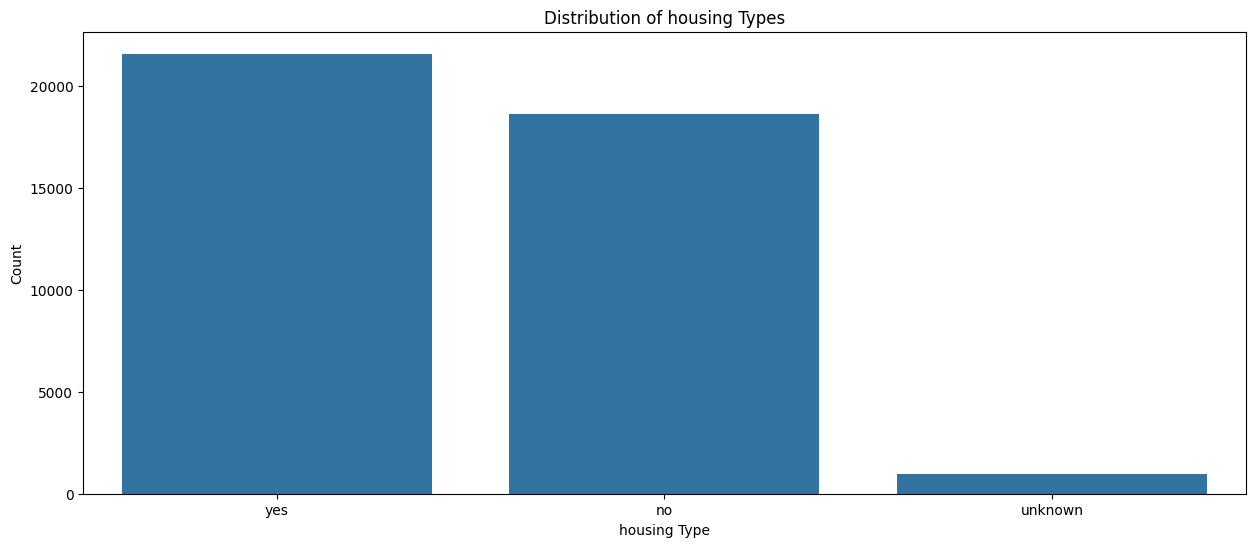

mean is:  13729.333333333334
No


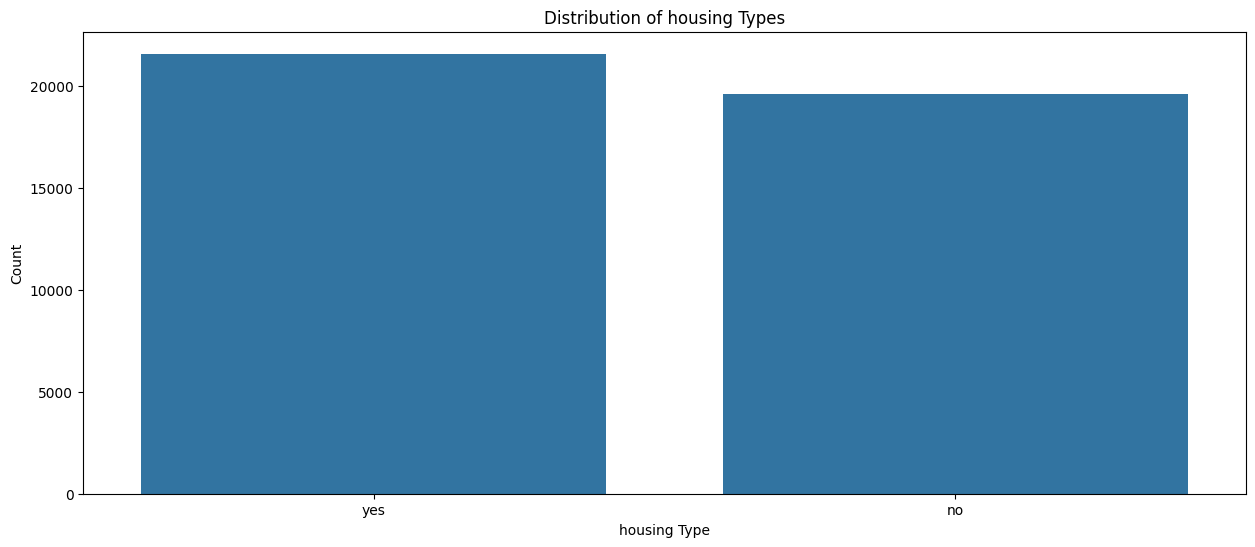

In [ ]:
df[df['housing'].str.contains('unknown')].count()
df[df['housing'].str.contains('unknown')]

plt.figure(figsize=(15, 6))
sns.countplot(x='housing', data=df, order = df['housing'].value_counts().index)
plt.title('Distribution of housing Types')
plt.ylabel('Count')
plt.xlabel('housing Type')
plt.show()

housing_counts = df['housing'].value_counts()
mean_housing_count = housing_counts.mean()
print("mean is: ",mean_housing_count)

difference=[]
for i in range (len(df['housing'].unique())):
  difference.append(abs(housing_counts.iloc[i] - mean_housing_count))

min_diff=np.min(difference)
replace_housing_title=''
for j in range(len(difference)):
  if difference[j]==min_diff:
    replace_housing_title=housing_counts.index[j].title()
    print(replace_housing_title)

#replacing unknown values with no
df['housing'] = df['housing'].replace('unknown',replace_housing_title.lower())

plt.figure(figsize=(15, 6))
sns.countplot(x='housing', data=df, order = df['housing'].value_counts().index)
plt.title('Distribution of housing Types')
plt.ylabel('Count')
plt.xlabel('housing Type')
plt.show()

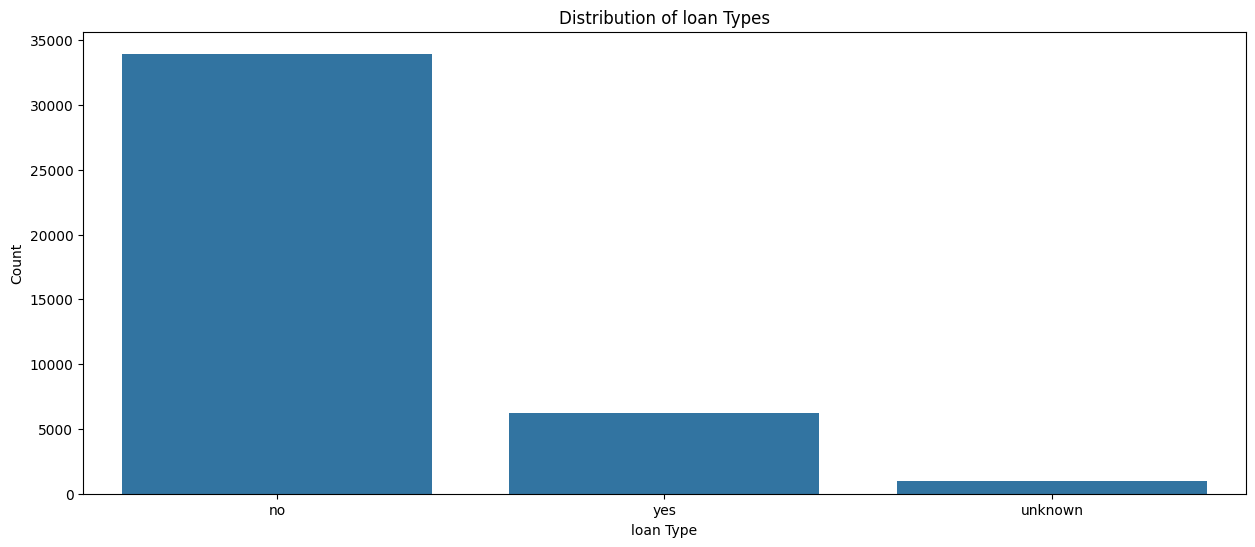

mean is:  13729.333333333334
Yes


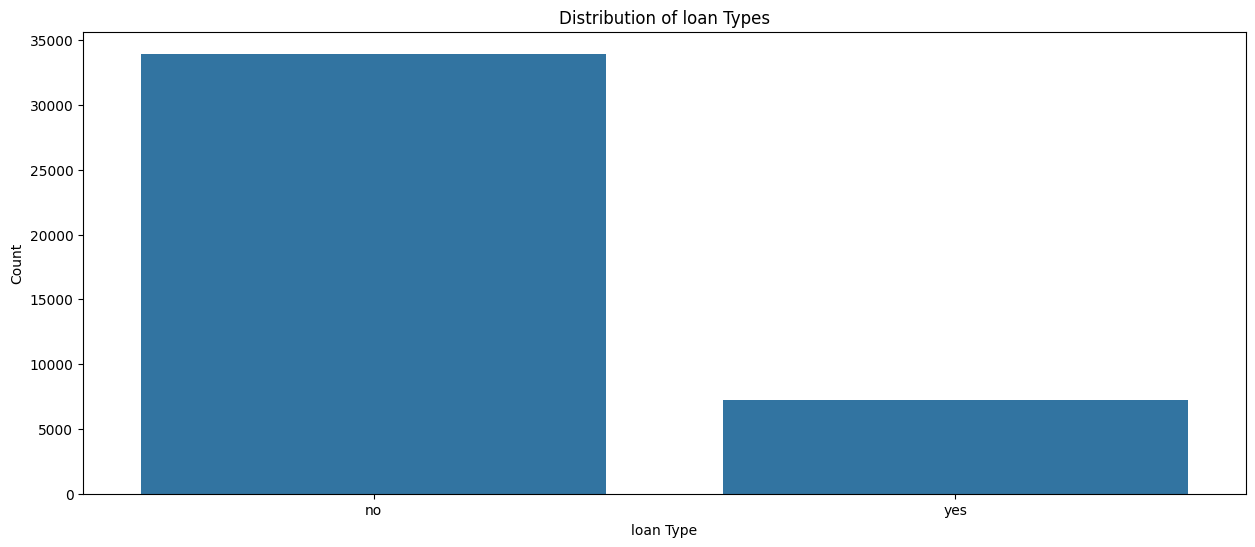

In [ ]:
df[df['loan'].str.contains('unknown')].count()
df[df['loan'].str.contains('unknown')]

plt.figure(figsize=(15, 6))
sns.countplot(x='loan', data=df, order = df['loan'].value_counts().index)
plt.title('Distribution of loan Types')
plt.ylabel('Count')
plt.xlabel('loan Type')
plt.show()

loan_counts = df['loan'].value_counts()
mean_loan_count = loan_counts.mean()
print("mean is: ",mean_loan_count)

difference=[]
for i in range (len(df['loan'].unique())):
  difference.append(abs(loan_counts.iloc[i] - mean_loan_count))

min_diff=np.min(difference)
replace_loan_title=''
for j in range(len(difference)):
  if difference[j]==min_diff:
    replace_loan_title=loan_counts.index[j].title()
    print(replace_loan_title)

#replacing unknown values with yes
df['loan'] = df['loan'].replace('unknown',replace_loan_title.lower())

plt.figure(figsize=(15, 6))
sns.countplot(x='loan', data=df, order = df['loan'].value_counts().index)
plt.title('Distribution of loan Types')
plt.ylabel('Count')
plt.xlabel('loan Type')
plt.show()





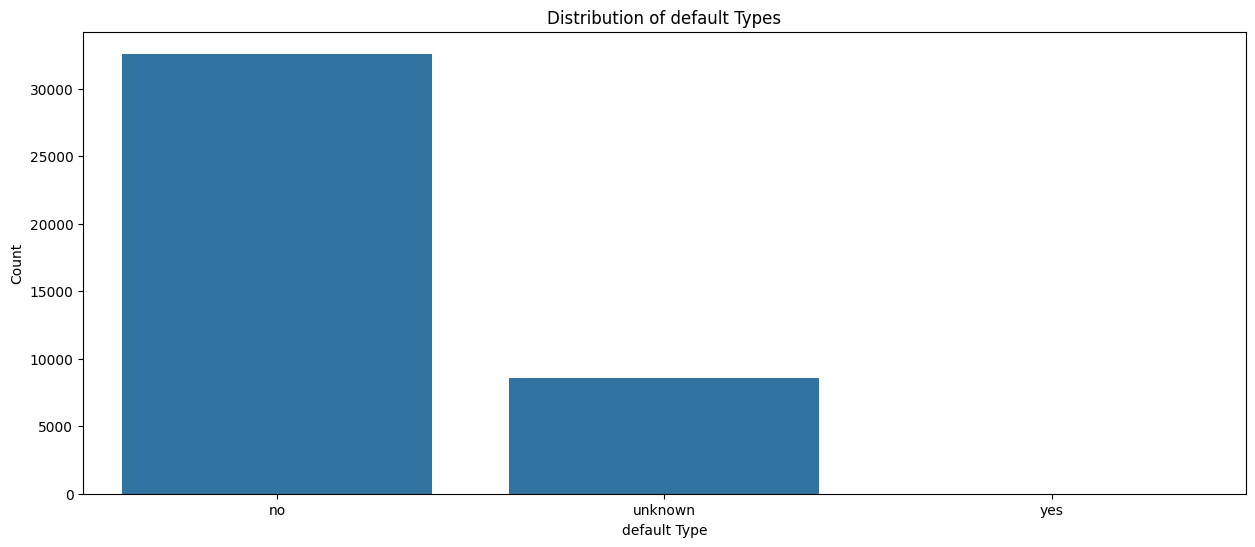

mean is:  13729.333333333334
Unknown


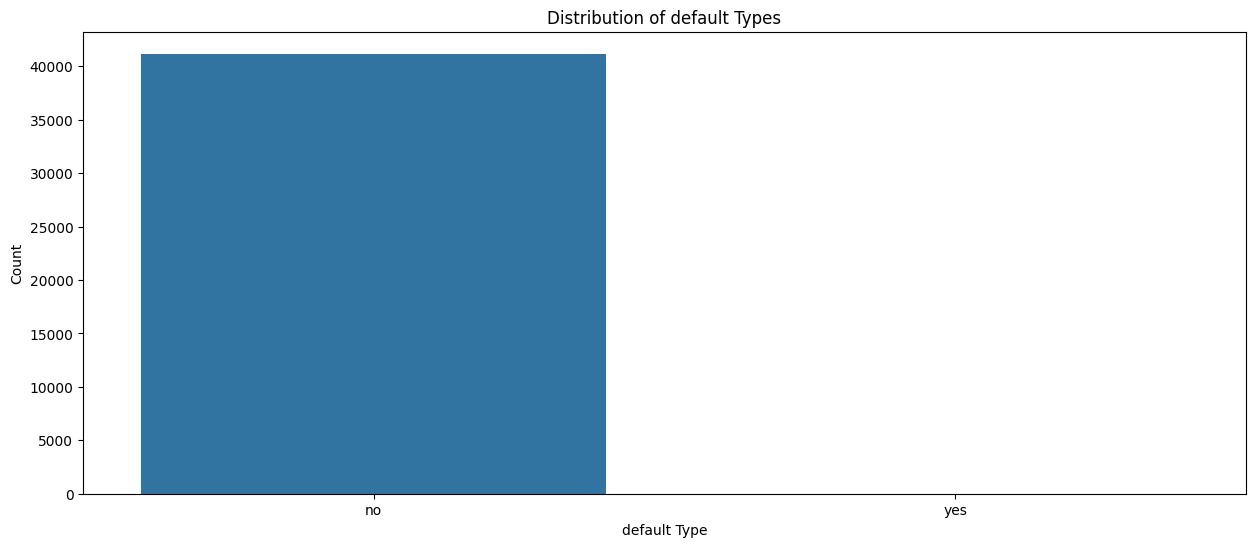

In [ ]:
df[df['default'].str.contains('unknown')].count()

df[df['default'].str.contains('unknown')]

plt.figure(figsize=(15, 6))
sns.countplot(x='default', data=df, order = df['default'].value_counts().index)
plt.title('Distribution of default Types')
plt.ylabel('Count')
plt.xlabel('default Type')
plt.show()

default_counts = df['default'].value_counts()
mean_default_count = default_counts.mean()
print("mean is: ",mean_default_count)

difference=[]
for i in range (len(df['default'].unique())):
  difference.append(abs(default_counts.iloc[i] - mean_default_count))

min_diff=np.min(difference)
replace_default_title=''
for j in range(len(difference)):
  if difference[j]==min_diff:
    replace_default_title=default_counts.index[j].title()
    print(replace_default_title)


#replacing unknown values with yes
df['default'] = df['default'].replace('unknown','no')

plt.figure(figsize=(15, 6))
sns.countplot(x='default', data=df, order = df['default'].value_counts().index)
plt.title('Distribution of default Types')
plt.ylabel('Count')
plt.xlabel('default Type')
plt.show()


In [ ]:
categorical_cols = ['job', 'contact']
data_to_encode = df[categorical_cols]

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
encoder.fit(data_to_encode)

encoded_data = encoder.transform(data_to_encode)

encoded_df = pd.DataFrame(encoded_data, columns=encoder.get_feature_names_out(categorical_cols))

df = pd.concat([df.drop(columns=categorical_cols), encoded_df], axis=1)

print(df)

       age  marital            education default housing loan month  \
0       56  married             basic.4y      no      no   no   may   
1       57  married          high.school      no      no   no   may   
2       37  married          high.school      no     yes   no   may   
3       40  married             basic.6y      no      no   no   may   
4       56  married          high.school      no      no  yes   may   
...    ...      ...                  ...     ...     ...  ...   ...   
41183   73  married  professional.course      no     yes   no   nov   
41184   46  married  professional.course      no      no   no   nov   
41185   56  married    university.degree      no     yes   no   nov   
41186   44  married  professional.course      no      no   no   nov   
41187   74  married  professional.course      no     yes   no   nov   

      day_of_week  duration  campaign  ...  job_housemaid  job_management  \
0             mon       261         1  ...            1.0             

In [ ]:
print('marital:',df['marital'].unique())
print('education:',df['education'].unique())
print('default:',df['default'].unique())
print('housing:',df['housing'].unique())
print('loan:',df['loan'].unique())
print('month:',df['month'].unique())
print('day_of_week:',df['day_of_week'].unique())
print('poutcome:',df['poutcome'].unique())
print('y:',df['y'].unique())

marital: ['married' 'single' 'divorced']
education: ['basic.4y' 'high.school' 'basic.6y' 'basic.9y' 'professional.course'
 'university.degree' 'illiterate']
default: ['no' 'yes']
housing: ['no' 'yes']
loan: ['no' 'yes']
month: ['may' 'jun' 'jul' 'aug' 'oct' 'nov' 'dec' 'mar' 'apr' 'sep']
day_of_week: ['mon' 'tue' 'wed' 'thu' 'fri']
poutcome: ['nonexistent' 'failure' 'success']
y: ['no' 'yes']


In [ ]:
#for marital
encoder = OrdinalEncoder(categories=[['single','married','divorced']])
df['marital_encoded'] = encoder.fit_transform(df[['marital']])


#for education
encoder = OrdinalEncoder(categories=[['illiterate','high.school','professional.course','basic.4y','university.degree','basic.6y', 'basic.9y']])
df['education_encoded'] = encoder.fit_transform(df[['education']])

#for default
encoder = OrdinalEncoder(categories=[['no' ,'yes' ]])
df['default_encoded'] = encoder.fit_transform(df[['default']])

#for housing
encoder = OrdinalEncoder(categories=[['no' ,'yes' ]])
df['housing_encoded'] = encoder.fit_transform(df[['housing']])

#for loan
encoder = OrdinalEncoder(categories=[['no' ,'yes' ]])
df['loan_encoded'] = encoder.fit_transform(df[['loan']])

#for poutcome
encoder = OrdinalEncoder(categories=[['failure' ,'success','nonexistent']])
df['poutcome_encoded'] = encoder.fit_transform(df[['poutcome']])

#for y
encoder = OrdinalEncoder(categories=[['no' ,'yes']])
df['y_encoded'] = encoder.fit_transform(df[['y']])


#for month
encoder = OrdinalEncoder(categories=[['mar','apr','may','jun' ,'jul','aug','sep','oct','nov','dec']])
df['month_encoded'] = encoder.fit_transform(df[['month']])+3


#for days of week
encoder = OrdinalEncoder(categories=[['mon' ,'tue' ,'wed', 'thu' ,'fri']])
df['day_of_week_encoded'] = encoder.fit_transform(df[['day_of_week']])+1

print(df)

       age  marital            education default housing loan month  \
0       56  married             basic.4y      no      no   no   may   
1       57  married          high.school      no      no   no   may   
2       37  married          high.school      no     yes   no   may   
3       40  married             basic.6y      no      no   no   may   
4       56  married          high.school      no      no  yes   may   
...    ...      ...                  ...     ...     ...  ...   ...   
41183   73  married  professional.course      no     yes   no   nov   
41184   46  married  professional.course      no      no   no   nov   
41185   56  married    university.degree      no     yes   no   nov   
41186   44  married  professional.course      no      no   no   nov   
41187   74  married  professional.course      no     yes   no   nov   

      day_of_week  duration  campaign  ...  contact_telephone  \
0             mon       261         1  ...                1.0   
1             mon

In [ ]:
df.dtypes

,0
age,int64
marital,object
education,object
default,object
housing,object
loan,object
month,object
day_of_week,object
duration,int64
campaign,int64


In [ ]:
df.groupby('y').mean(numeric_only=True)

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,...,contact_telephone,marital_encoded,education_encoded,default_encoded,housing_encoded,loan_encoded,poutcome_encoded,y_encoded,month_encoded,day_of_week_encoded
y,,,,,,,,,,,,,,,,,,,,,
no,39.911185,220.844807,2.633085,984.113878,0.132374,0.248875,93.603757,-40.593097,3.811491,5176.166600,...,0.390090,0.839116,3.226661,0.000082,0.521752,0.176426,1.787321,0.0,6.580853,2.974527
yes,40.913147,553.191164,2.051724,792.035560,0.492672,-1.233448,93.354386,-39.789784,2.123135,5095.115991,...,0.169612,0.750862,3.117457,0.000000,0.540302,0.170259,1.546552,1.0,6.820905,3.019397


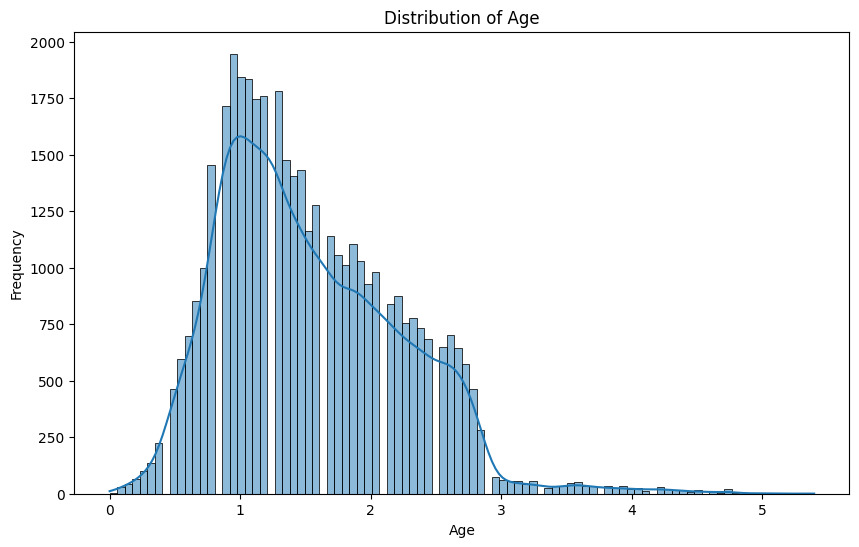

In [ ]:
# Robust Scaling for age
robust_scaler = RobustScaler()
df['age'] = robust_scaler.fit_transform(df[['age']])-np.min(robust_scaler.fit_transform(df[['age']]))

plt.figure(figsize=(10, 6))
sns.histplot(df['age'], kde=True)
plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

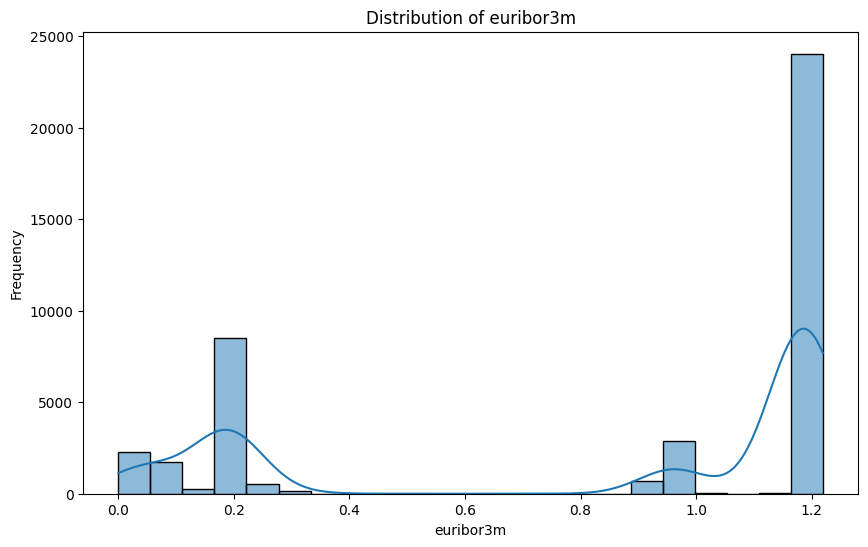

In [ ]:
# Robust Scaling for euribor3m
robust_scaler = RobustScaler()
df['euribor3m'] = robust_scaler.fit_transform(df[['euribor3m']])-np.min(robust_scaler.fit_transform(df[['euribor3m']]))

plt.figure(figsize=(10, 6))
sns.histplot(df['euribor3m'], kde=True)
plt.title('Distribution of euribor3m')
plt.xlabel('euribor3m')
plt.ylabel('Frequency')
plt.show()

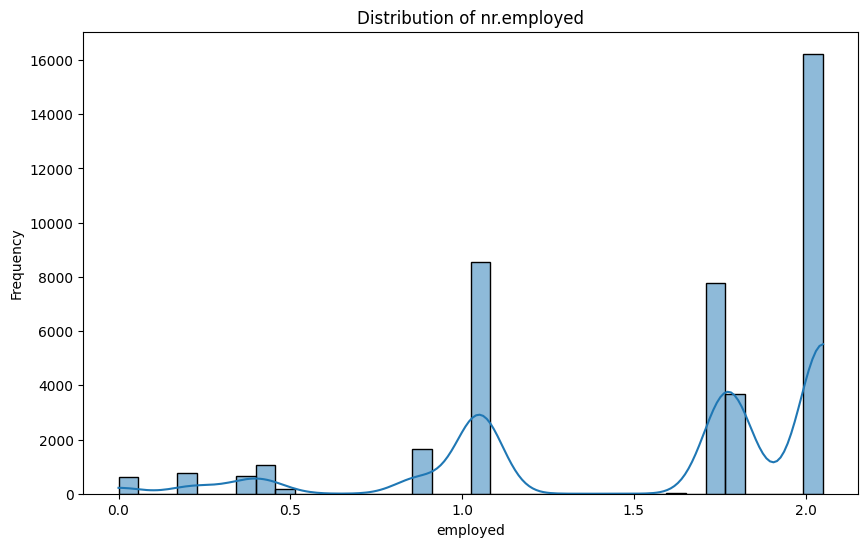

In [ ]:
# Robust Scaling for nr.employed
robust_scaler = RobustScaler()
df['nr.employed'] = robust_scaler.fit_transform(df[['nr.employed']])-np.min(robust_scaler.fit_transform(df[['nr.employed']]))

plt.figure(figsize=(10, 6))
sns.histplot(df['nr.employed'], kde=True)
plt.title('Distribution of nr.employed')
plt.xlabel('employed')
plt.ylabel('Frequency')
plt.show()

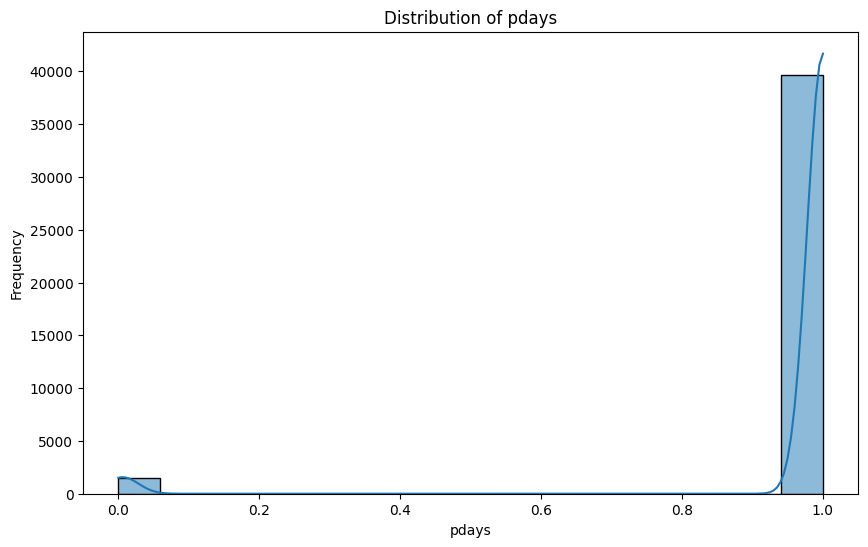

In [ ]:
# Robust Scaling for pdays
robust_scaler = RobustScaler()
df['pdays'] = (robust_scaler.fit_transform(df[['pdays']])-np.min(robust_scaler.fit_transform(df[['pdays']])))/np.max(df['pdays'])

plt.figure(figsize=(10, 6))
sns.histplot(df['pdays'], kde=True)
plt.title('Distribution of pdays')
plt.xlabel('pdays')
plt.ylabel('Frequency')
plt.show()



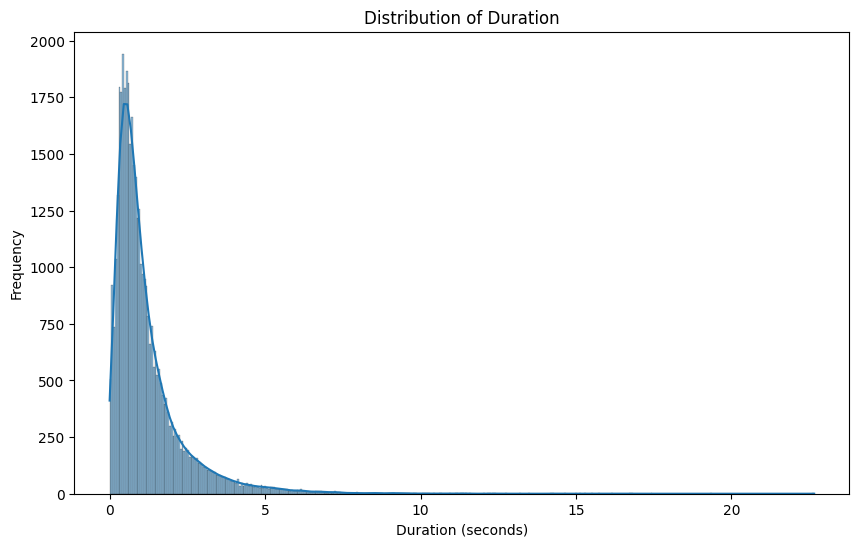

In [ ]:
# Robust Scaling for duration
robust_scaler = RobustScaler()
df['duration'] = (robust_scaler.fit_transform(df[['duration']])-np.min(robust_scaler.fit_transform(df[['duration']])))

plt.figure(figsize=(10, 6))
sns.histplot(df['duration'], kde=True)
plt.title('Distribution of Duration')
plt.xlabel('Duration (seconds)')
plt.ylabel('Frequency')
plt.show()

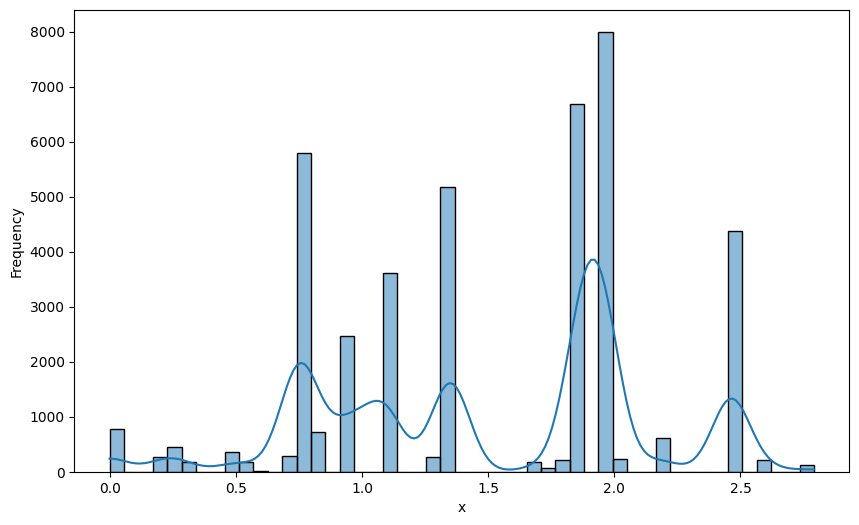

In [ ]:
# Robust Scaling for cons.price.idx
robust_scaler = RobustScaler()
df['cons.price.idx'] = (robust_scaler.fit_transform(df[['cons.price.idx']])-np.min(robust_scaler.fit_transform(df[['cons.price.idx']])))

plt.figure(figsize=(10, 6))
sns.histplot(df['cons.price.idx'], kde=True)
plt.xlabel('x')
plt.ylabel('Frequency')
plt.show()

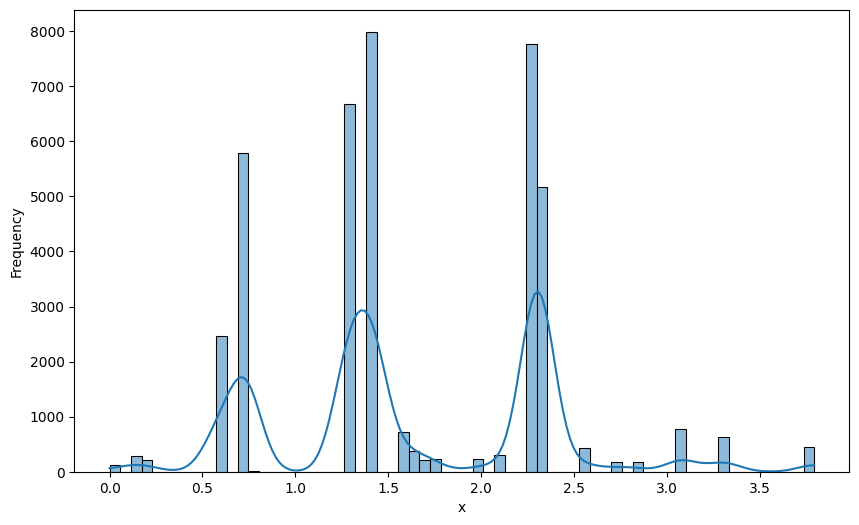

In [ ]:
# Robust Scaling for cons.conf.idx
robust_scaler = RobustScaler()
df['cons.conf.idx'] = (robust_scaler.fit_transform(df[['cons.conf.idx']])-np.min(robust_scaler.fit_transform(df[['cons.conf.idx']])))

plt.figure(figsize=(10, 6))
sns.histplot(df['cons.conf.idx'], kde=True)
plt.xlabel('x')
plt.ylabel('Frequency')
plt.show()

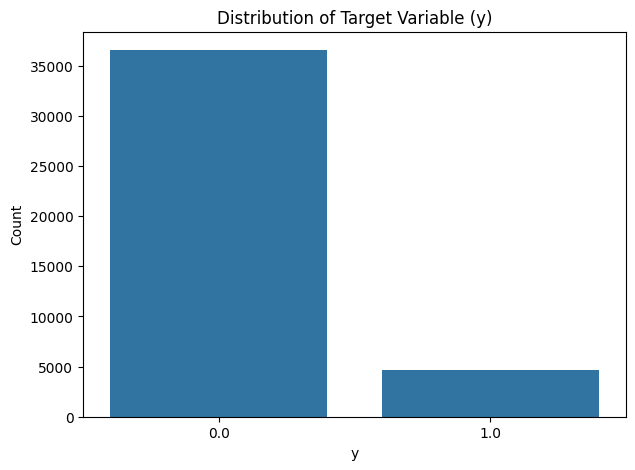

In [ ]:
plt.figure(figsize=(7, 5))
sns.countplot(x='y_encoded', data=df, order = df['y_encoded'].value_counts().index)
plt.title('Distribution of Target Variable (y)')
plt.xlabel('y')
plt.ylabel('Count')
plt.show()

In [ ]:
X = df.drop([ 'marital', 'education', 'default', 'housing', 'loan', 'month', 'day_of_week','y','poutcome','month', 'day_of_week', 'y_encoded'], axis=1)
y = df['y_encoded']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

sm = SMOTE(random_state = 2)
X_train_resample, y_train_resample = sm.fit_resample(X_train, y_train)

In [ ]:
print(f" X_train: {X_train.shape}")
print(f"X_train_resample: {X_train_resample.shape}")
print(f"y_train:\n{y_train.value_counts()}")
print(f"y_train_resample:\n{y_train_resample.value_counts()}")

 X_train: (28831, 31)
X_train_resample: (51158, 31)
y_train:
y_encoded
0.0    25579
1.0     3252
Name: count, dtype: int64
y_train_resample:
y_encoded
0.0    25579
1.0    25579
Name: count, dtype: int64


 Decision Tree:

In [ ]:
#Decision Tree:
st=time.time()
param_grid = {
  'criterion': ['gini', 'entropy', 'log_loss'],
  'max_depth': [3, 5, 7, 9, 11, 15],
}
dtree = DecisionTreeClassifier(random_state=2)
grid_search = GridSearchCV(estimator=dtree, param_grid=param_grid, cv=5, scoring='f1', n_jobs=-1)

grid_search.fit(X_train_resample, y_train_resample)

print("Best parameters found:", grid_search.best_params_)
best_dtree = grid_search.best_estimator_
et=time.time()

print("time",et-st)

Best parameters found: {'criterion': 'gini', 'max_depth': 15}
time 34.18194937705994


In [ ]:
dtree1=DecisionTreeClassifier(random_state=2,max_depth=15,criterion='gini')
st=time.time()
dtree1.fit(X_train_resample, y_train_resample)
et=time.time()
time_tree=et-st
print(" tree time",time_tree)
print(dtree1.score(X_train_resample, y_train_resample))

 tree time 1.3217735290527344
0.9706204308221588


In [ ]:
best_dt_model = grid_search.best_estimator_
feature_names = X_train_resample.columns.tolist()
target_names = [str(x) for x in y_train_resample.unique().tolist()]

dot_data = export_graphviz(
    best_dt_model,
    out_file=None,
    feature_names=feature_names,
    class_names=target_names,
    filled=True,
    rounded=True,
    special_characters=True,
    proportion=True
)

dot_data = dot_data.replace('digraph Tree {', 'digraph Tree {\n  size="300,10!";')

graph = graphviz.Source(dot_data, format='png', engine='dot')

graph

In [ ]:
y_pred_tree = best_dtree.predict(X_test)
accuracy_tree = accuracy_score(y_test, y_pred_tree)
print("Accuracy on test set with best parameters:", accuracy_tree)


Accuracy on test set with best parameters: 0.8860564862021526


Confusion Matrix:
[[10007   962]
 [  446   942]]


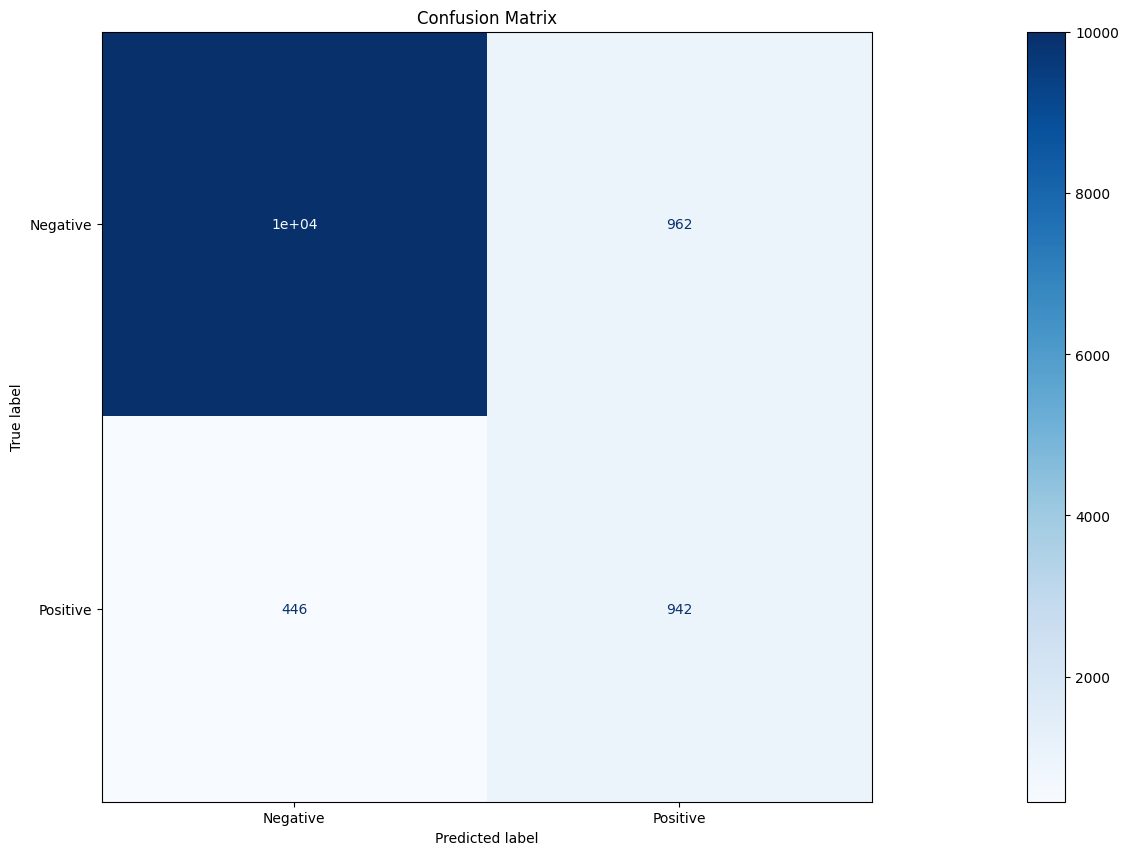

In [ ]:
cm_tree = confusion_matrix(y_test, y_pred_tree)

print("Confusion Matrix:")
print(cm_tree)

class_labels = ['Negative', 'Positive']
disp = ConfusionMatrixDisplay(confusion_matrix=cm_tree, display_labels=class_labels)
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.show()

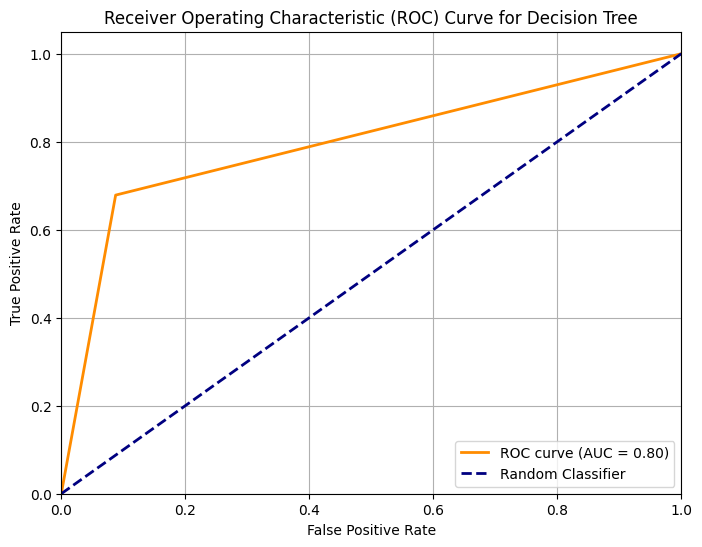

In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, y_pred_tree)

roc_auc_tree = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc_tree:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for Decision Tree')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


In [ ]:
precision_tree = precision_score(y_test, y_pred_tree)

print(f"Precision: {precision_tree}")

Precision: 0.4947478991596639


In [ ]:
recall_tree = recall_score(y_test, y_pred_tree)

print(f"Recall: {recall_tree}")

Recall: 0.6786743515850144


In [ ]:
f1_yes_tree = f1_score(y_test, y_pred_tree, average='binary', pos_label=1)
f1_no_tree = f1_score(y_test, y_pred_tree, average='binary', pos_label=0)

print(f"F1 score For Yes: {f1_yes_tree}")
print(f"F1 score For No: {f1_no_tree}")

F1 score For Yes: 0.5722964763061968
F1 score For No: 0.9342731771076463


SVM:

In [ ]:
#SVM:
st=time.time()
param_grid = {
  'kernel': ['linear', 'rbf', 'poly'],
}

X_svm_subset, _, y_svm_subset, _ = train_test_split(X_train_resample, y_train_resample, test_size=0.8, random_state=2)

grid_search = GridSearchCV(SVC(), param_grid, cv=5, scoring='f1', verbose=3)
grid_search.fit(X_svm_subset, y_svm_subset)

print("Best parameters found: ", grid_search.best_params_)
print("Best cross-validation score: ", grid_search.best_score_)
best_svm_model = grid_search.best_estimator_
et=time.time()

print("time: ",et-st)


Fitting 5 folds for each of 3 candidates, totalling 15 fits
[CV 1/5] END .....................kernel=linear;, score=0.868 total time=   4.8s
[CV 2/5] END .....................kernel=linear;, score=0.867 total time=   4.2s
[CV 3/5] END .....................kernel=linear;, score=0.875 total time=   4.2s
[CV 4/5] END .....................kernel=linear;, score=0.873 total time=   4.9s
[CV 5/5] END .....................kernel=linear;, score=0.855 total time=   4.0s
[CV 1/5] END ........................kernel=rbf;, score=0.886 total time=   2.3s
[CV 2/5] END ........................kernel=rbf;, score=0.886 total time=   2.5s
[CV 3/5] END ........................kernel=rbf;, score=0.887 total time=   3.2s
[CV 4/5] END ........................kernel=rbf;, score=0.880 total time=   2.3s
[CV 5/5] END ........................kernel=rbf;, score=0.878 total time=   2.3s
[CV 1/5] END .......................kernel=poly;, score=0.877 total time=   2.3s
[CV 2/5] END .......................kernel=poly;,

In [ ]:
svm_model = SVC(kernel='rbf',random_state=2)
st=time.time()
svm_model.fit(X_svm_subset, y_svm_subset)
et=time.time()

time_svm=et-st
print("time", time_svm)

print("score on training data : ",svm_model.score(X_svm_subset, y_svm_subset))


time 3.2079522609710693
score on training data :  0.8857394194115922


In [ ]:
y_pred_SVM = svm_model.predict(X_test)

accuracy_svm = accuracy_score(y_test, y_pred_SVM)
print(f"Accuracy on test data: {accuracy_svm}")


Accuracy on test data: 0.8498826576029781


Confusion Matrix:
[[9234 1735]
 [ 120 1268]]


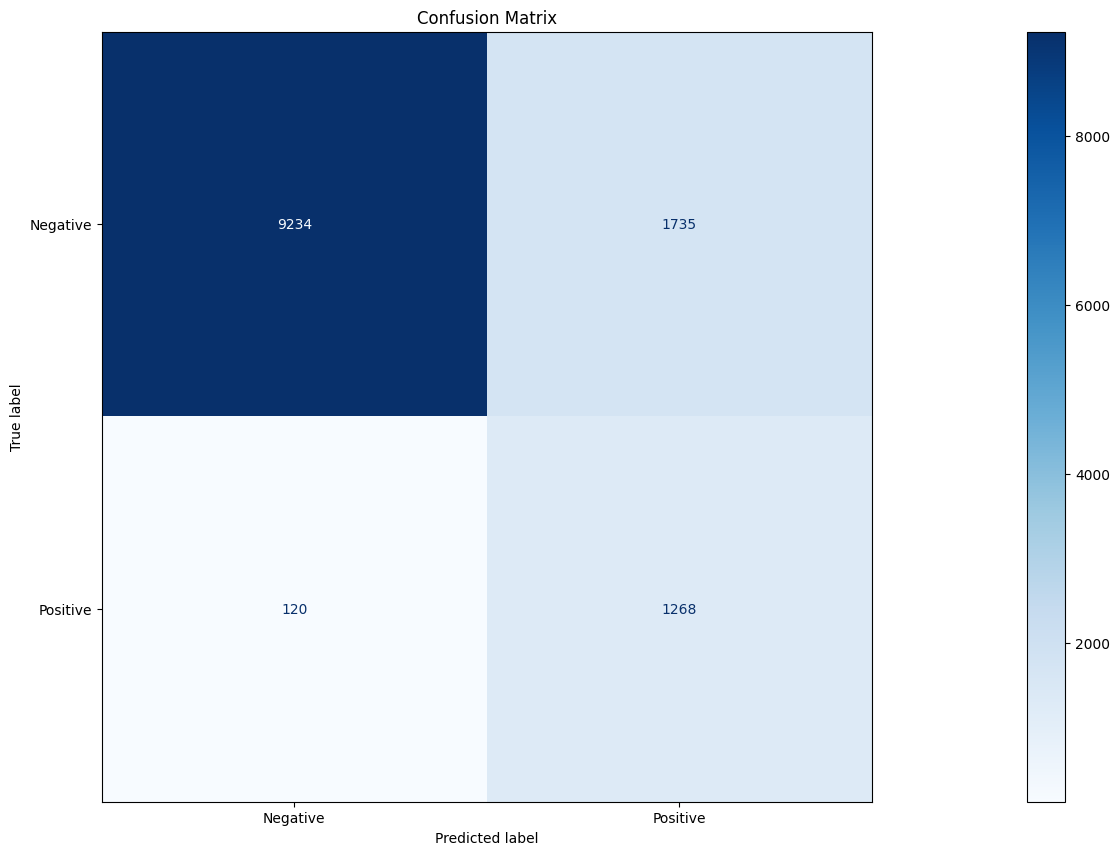

In [ ]:
cm_svm = confusion_matrix(y_test, y_pred_SVM)

print("Confusion Matrix:")
print(cm_svm)

class_labels = ['Negative', 'Positive']
disp = ConfusionMatrixDisplay(confusion_matrix=cm_svm, display_labels=class_labels)
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.show()

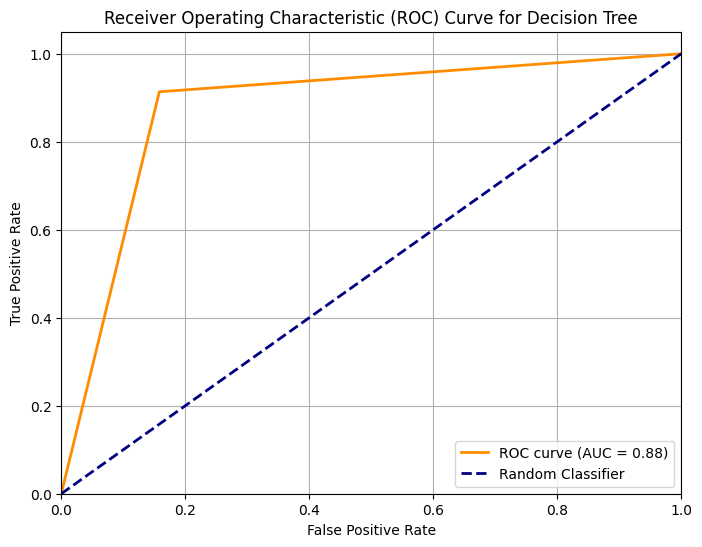

In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, y_pred_SVM)

roc_auc_svm = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc_svm:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for Decision Tree')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


In [ ]:
precision_svm = precision_score(y_test, y_pred_SVM)

print(f"Precision: {precision_svm}")

Precision: 0.42224442224442227


In [ ]:
recall_svm = recall_score(y_test, y_pred_SVM)

print(f"Recall: {recall_svm}")

Recall: 0.9135446685878963


In [ ]:
f1_yes_svm = f1_score(y_test, y_pred_SVM, average='binary', pos_label=1)
f1_no_svm = f1_score(y_test, y_pred_SVM, average='binary', pos_label=0)

print(f"F1 score For Yes: {f1_yes_svm}")
print(f"F1 score For No: {f1_no_svm}")

F1 score For Yes: 0.5775449783648372
F1 score For No: 0.9087241056930572


Logistic Regretion

In [ ]:
st=time.time()

log_reg = LogisticRegression(max_iter=1000,random_state=2)
param_grid = {
    'penalty': ['l1', 'l2'],
    'C': [0.001, 0.01, 0.1, 1, 10, 100, 1000],
    'solver': ['liblinear']
}

grid_search = GridSearchCV(estimator=log_reg,param_grid=param_grid,cv=5, scoring='f1', n_jobs=-1, verbose=1)

grid_search.fit(X_train_resample, y_train_resample)
et=time.time()

print("time: ",et-st)
print(f"Best parameters: {grid_search.best_params_}")
print(f"Best cross-validation score: {grid_search.best_score_:.4f}")

Fitting 5 folds for each of 14 candidates, totalling 70 fits
time:  118.33983969688416
Best parameters: {'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}
Best cross-validation score: 0.8659


In [ ]:
LR = LogisticRegression(penalty='l2',C= 0.1,solver='liblinear', random_state=2)
st=time.time()
LR.fit(X_train_resample, y_train_resample)
et=time.time()

time_LR=et-st
print("time", time_LR)
print("score on training data : ",LR.score(X_train_resample, y_train_resample))

time 0.5313034057617188
score on training data :  0.8650846397435397


In [ ]:
y_pred_LR = LR.predict(X_test)

accuracy_LR = accuracy_score(y_test, y_pred_LR)
print(f"Accuracy on test data: {accuracy_LR}")

Accuracy on test data: 0.8644492999919074


Confusion Matrix:
[[9490 1479]
 [ 196 1192]]


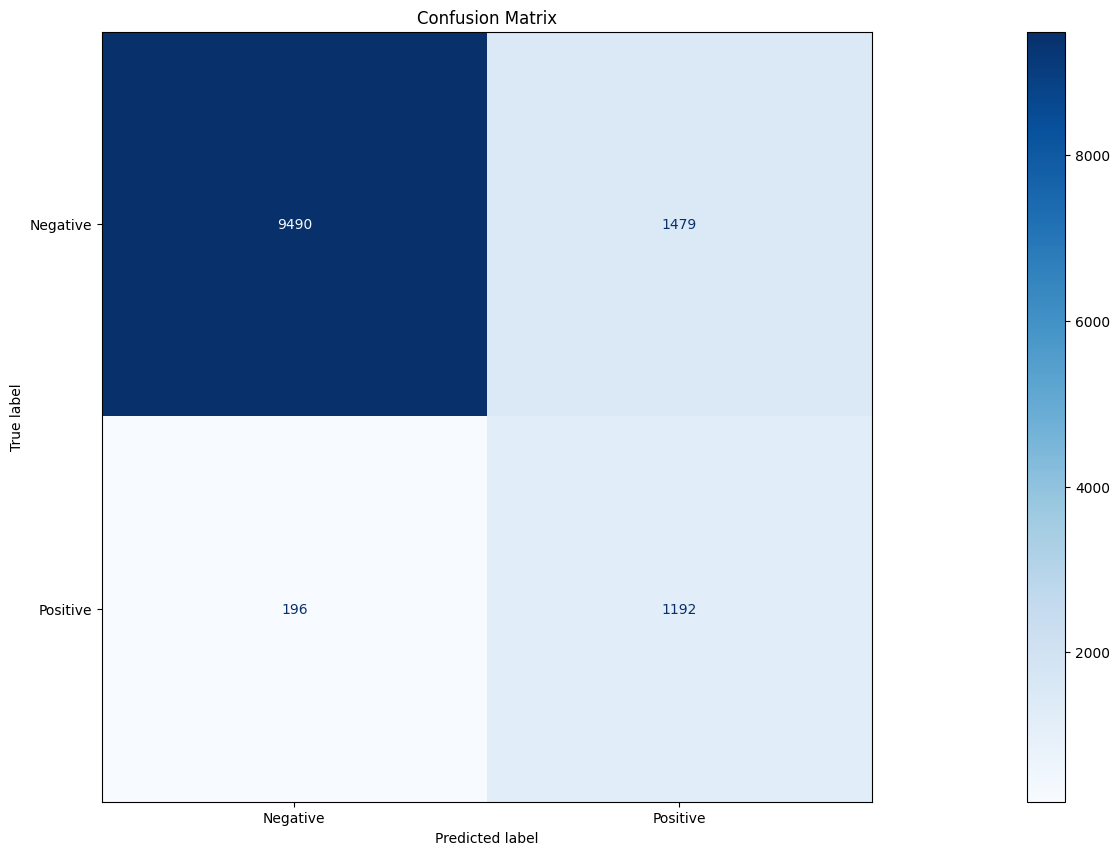

In [ ]:
cm_LR = confusion_matrix(y_test, y_pred_LR)

print("Confusion Matrix:")
print(cm_LR)

class_labels = ['Negative', 'Positive']
disp = ConfusionMatrixDisplay(confusion_matrix=cm_LR, display_labels=class_labels)
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.show()

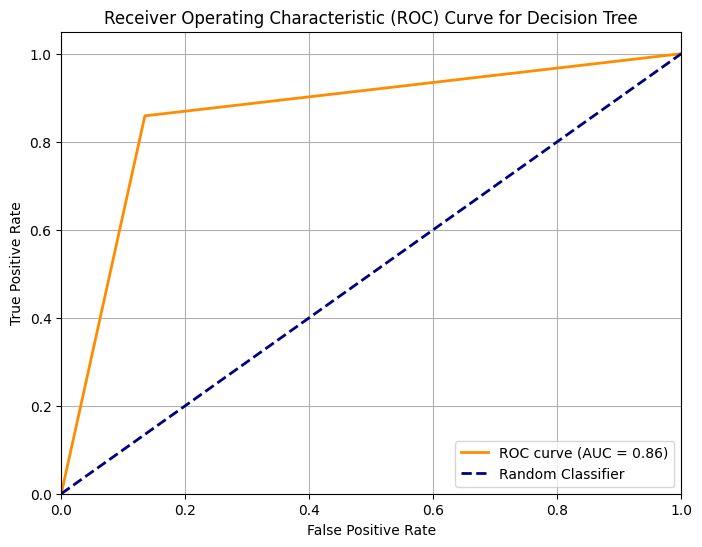

In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, y_pred_LR)

roc_auc_LR = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc_LR:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for Decision Tree')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


In [ ]:
precision_LR = precision_score(y_test, y_pred_LR)

print(f"Precision: {precision_LR}")

Precision: 0.44627480344440285


In [ ]:
recall_LR = recall_score(y_test, y_pred_LR)

print(f"Recall: {recall_LR}")

Recall: 0.8587896253602305


In [ ]:
f1_yes_LR = f1_score(y_test, y_pred_LR, average='binary', pos_label=1)
f1_no_LR = f1_score(y_test, y_pred_LR, average='binary', pos_label=0)

print(f"F1 score For Yes: {f1_yes_LR}")
print(f"F1 score For No: {f1_no_LR}")

F1 score For Yes: 0.5873367824587337
F1 score For No: 0.9189058339385137


KNN

In [ ]:
knn = KNeighborsClassifier()
param_grid = {
  'n_neighbors': range(5, 15,2),
  'metric': ['euclidean', 'manhattan', 'minkowski']
}
grid_search = GridSearchCV(estimator=knn,param_grid=param_grid,scoring='f1',cv=5,n_jobs=-1)
grid_search.fit(X_train_resample, y_train_resample)

print("Best parameters found:", grid_search.best_params_)
print("Best cross-validation score:", grid_search.best_score_)

Best parameters found: {'metric': 'manhattan', 'n_neighbors': 5}
Best cross-validation score: 0.9435677136175112


In [ ]:
KNN = KNeighborsClassifier(n_neighbors= 5 , metric='manhattan')
st=time.time()
KNN.fit(X_train_resample, y_train_resample)
et=time.time()

time_knn=et-st

print("time", time_knn)
print("score on training data : ",KNN.score(X_train_resample, y_train_resample))

time 0.0813894271850586
score on training data :  0.958911607177763


In [ ]:
y_pred_KNN = KNN.predict(X_test)

accuracy_knn = accuracy_score(y_test, y_pred_KNN)
print(f"Accuracy on test data: {accuracy_knn}")

Accuracy on test data: 0.8720563243505706


Confusion Matrix:
[[9812 1157]
 [ 424  964]]


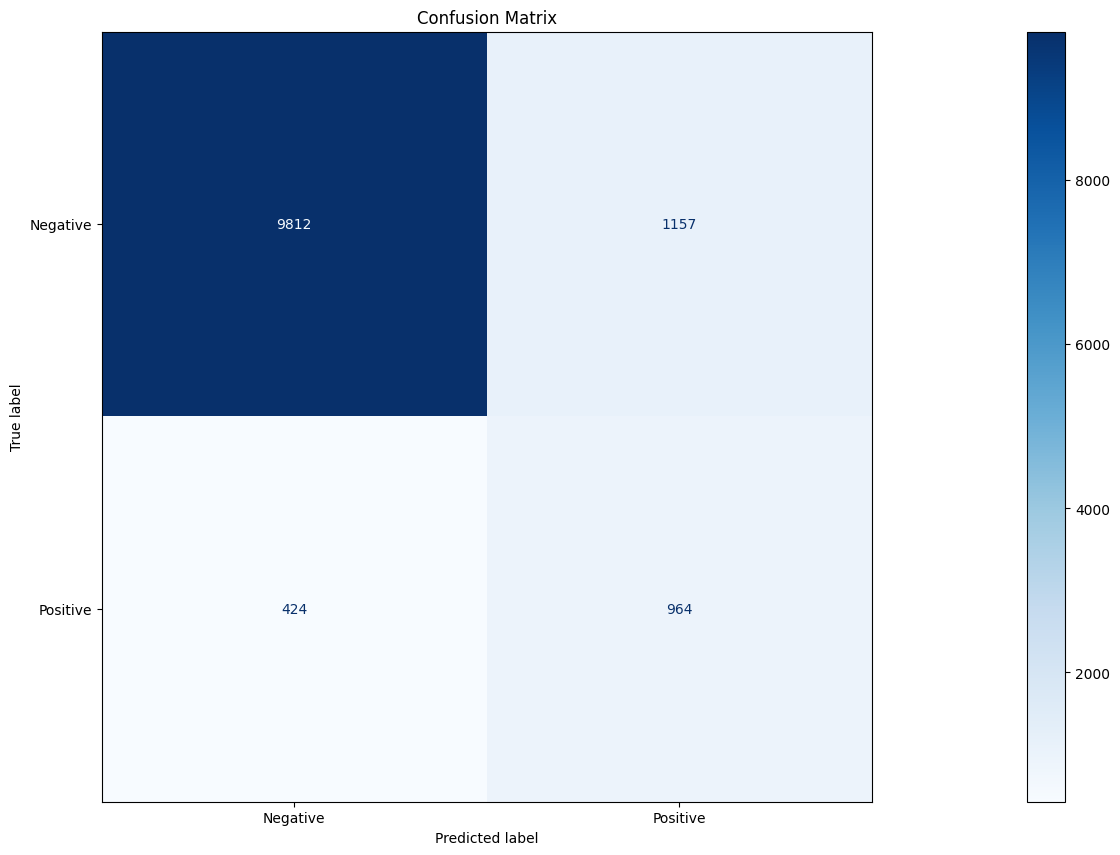

In [ ]:
cm_knn = confusion_matrix(y_test, y_pred_KNN)

print("Confusion Matrix:")
print(cm_knn)

class_labels = ['Negative', 'Positive']
disp = ConfusionMatrixDisplay(confusion_matrix=cm_knn, display_labels=class_labels)
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.show()

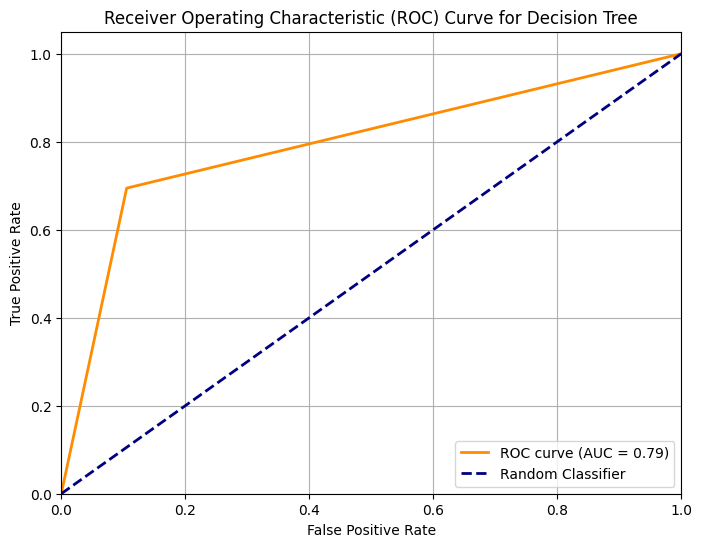

In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, y_pred_KNN)

roc_auc_knn = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc_knn:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for Decision Tree')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


In [ ]:
precision_knn = precision_score(y_test, y_pred_KNN)

print(f"Precision: {precision_knn}")

Precision: 0.4545025931164545


In [ ]:
recall_knn = recall_score(y_test, y_pred_KNN)

print(f"Recall: {recall_knn}")

Recall: 0.6945244956772334


In [ ]:
f1_yes_knn = f1_score(y_test, y_pred_KNN, average='binary', pos_label=1)
f1_no_knn = f1_score(y_test, y_pred_KNN, average='binary', pos_label=0)

print(f"F1 score For Yes: {f1_yes_knn}")
print(f"F1 score For No: {f1_no_knn}")

F1 score For Yes: 0.5494442861214021
F1 score For No: 0.9254421127092667


In [80]:
model_summary = [
    {
        'Model': 'Decision Tree',
        'Best Hyperparameters': "{'criterion': 'gini', 'max_depth': 15}",
        'Final Model Training Time (s)': time_tree,
        'Auc': roc_auc_tree,
        'accuracy': accuracy_tree,
        'precision':precision_tree,
        'recall': recall_tree,
        'F1 (Yes)': f1_yes_tree,
        'F1 (No)': f1_no_tree
    },
    {
        'Model': 'SVM',
        'Best Hyperparameters': "{'kernel': 'rbf'}",
        'Final Model Training Time (s)': time_svm,
        'Auc': roc_auc_svm,
        'accuracy': accuracy_svm,
        'precision':precision_svm,
        'recall': recall_svm,
        'F1 (Yes)': f1_yes_svm,
        'F1 (No)': f1_no_svm
    },
    {
        'Model': 'Logistic Regression',
        'Best Hyperparameters': "{'C': 0.1, 'penalty': 'l2'}",
        'Final Model Training Time (s)': time_LR,
        'Auc': roc_auc_LR,
        'accuracy': accuracy_LR,
        'precision':precision_LR,
        'recall': recall_LR,
        'F1 (Yes)': f1_yes_LR,
        'F1 (No)': f1_no_LR
    },
    {
        'Model': 'KNN',
        'Best Hyperparameters': "{'metric': 'manhattan', 'n_neighbors': 5}",
        'Final Model Training Time (s)': time_knn,
        'Auc': roc_auc_knn,
        'accuracy': accuracy_knn,
        'precision':precision_knn,
        'recall': recall_knn,
        'F1 (Yes)': f1_yes_knn,
        'F1 (No)': f1_no_knn
    }
]

summary_df = pd.DataFrame(model_summary)
display(summary_df)

,Model,Best Hyperparameters,Final Model Training Time (s),Auc,accuracy,precision,recall,F1 (Yes),F1 (No)
0,Decision Tree,"{'criterion': 'gini', 'max_depth': 15}",1.321774,0.795486,0.886056,0.494748,0.678674,0.572296,0.934273
1,SVM,{'kernel': 'rbf'},3.207952,0.877686,0.849883,0.422244,0.913545,0.577545,0.908724
2,Logistic Regression,"{'C': 0.1, 'penalty': 'l2'}",0.531303,0.861978,0.864449,0.446275,0.858790,0.587337,0.918906
3,KNN,"{'metric': 'manhattan', 'n_neighbors': 5}",0.081389,0.794523,0.872056,0.454503,0.694524,0.549444,0.925442


In [81]:
sorted_summary_df = summary_df.sort_values(by=['F1 (Yes)', 'Auc'], ascending=False).reset_index(drop=True)
display(sorted_summary_df)

,Model,Best Hyperparameters,Final Model Training Time (s),Auc,accuracy,precision,recall,F1 (Yes),F1 (No)
0,Logistic Regression,"{'C': 0.1, 'penalty': 'l2'}",0.531303,0.861978,0.864449,0.446275,0.858790,0.587337,0.918906
1,SVM,{'kernel': 'rbf'},3.207952,0.877686,0.849883,0.422244,0.913545,0.577545,0.908724
2,Decision Tree,"{'criterion': 'gini', 'max_depth': 15}",1.321774,0.795486,0.886056,0.494748,0.678674,0.572296,0.934273
3,KNN,"{'metric': 'manhattan', 'n_neighbors': 5}",0.081389,0.794523,0.872056,0.454503,0.694524,0.549444,0.925442


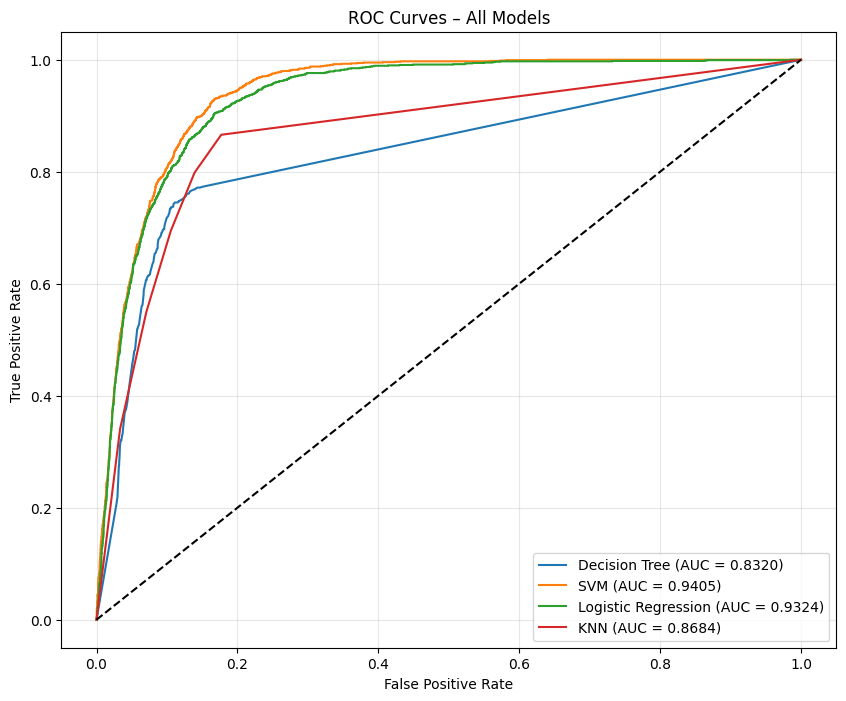

In [82]:
plt.figure(figsize=(10,8))

# Dictionary of already trained models
trained_models = {
    'Decision Tree': best_dtree,
    'SVM': svm_model,
    'Logistic Regression': LR,
    'KNN': KNN
}

for name, model in trained_models.items():
    # For SVC trained without probability=True, use decision_function
    if name == 'SVM':
        y_score = model.decision_function(X_test)
    else:
        y_score = model.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, y_score)
    auc = roc_auc_score(y_test, y_score)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.4f})')

plt.plot([0,1],[0,1],'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves – All Models')
plt.legend()
plt.grid(alpha=0.3)
plt.show()